# 14 Class balancing and augmentation arms (ST-GCN, final configuration)

Every arm here uses the same final ST-GCN configuration (`body_court` input, the tuned recipe in
`configs/stgcn_recipe.json`) and the same three reporting seeds (42, 123, 7). Only how the small classes are
handled changes. Results are reported on the test set; nothing is selected on it.

**Arms.**

| arm | augmentation | class balancing | source of results |
|---|---|---|---|
| `natural` | none | none, natural class frequencies | new runs |
| `sampler` | none | balanced sampler (duplication) | notebook 06, reused |
| `online_all` | current bundle on every class | balanced sampler | notebook 06, reused |
| `online_small` | current bundle on classes under 500 clips only | balanced sampler | new runs |
| `offline_to_500` | the original protocol: basic techniques generate synthetic clips for classes under 500 until each has 500, trained on that fixed enlarged set | none (already balanced) | new runs |

Reusing the two arms from notebook 06 is valid because they were trained with exactly this configuration and
these seeds. New runs: 3 arms times 3 seeds, 9 runs in all.

**Contrasts.**

| contrast | what it isolates |
|---|---|
| `sampler` vs `natural` | balancing by duplication |
| `online_all` vs `sampler` | augmentation applied to every class |
| `online_small` vs `sampler` | augmentation applied only where data is scarce |
| `online_small` vs `online_all` | whether leaving the large classes alone matters |
| `offline_to_500` vs `natural` | the original protocol against the raw dataset |
| `offline_to_500` vs `sampler` | fixed synthetic clips against plain duplication |

`offline_to_500` uses the basic family and the online arms use the advanced bundle, as in the original work
and in this project's pipeline respectively. The earlier family comparison (notebook 12) found them close on
validation, but the two factors (offline against online, basic against advanced) are not separated by this
design, and the comparison should be read that way.

**Reporting.** Metrics are computed from per clip predictions for every arm, so reused and new arms are
treated identically. Intervals combine seed to seed variation and test clip sampling (resampling seeds and
clips together), and a seed only Welch interval is shown beside it as a cross check. With three seeds both are
wide, and the notebook says so rather than hiding it.

Logs to `BadmintonPoseAnalysis/experiments/class_balancing_arms`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import glob
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy import stats
from sklearn.metrics import f1_score
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
sys.path.insert(0, REPO)
import dataset as ds
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/class_balancing_arms"
KEYPOINTS = f"{DATA}/keypoints_interp"
OFFLINE_ROOT = f"{DATA}/keypoints_offline_aug"
OUT = f"{OUTPUTS}/experiments/class_balancing_arms"
os.makedirs(OUT, exist_ok=True)

SEEDS = [42, 123, 7]
SPLITS = ("train", "val", "test")
NORMALISATION, USE_COURT = "body", True
NUM_WORKERS, EVAL_WORKERS = 20, 8
SMALL_THRESHOLD = int(os.environ.get("SMALL_THRESHOLD", 500))     # classes below this get augmented / built up
RARE_THRESHOLD = int(os.environ.get("RARE_THRESHOLD", 150))       # reporting group (as in notebook 13)
OFFLINE_TARGET = SMALL_THRESHOLD
N_BOOT, BOOT_SEED = 2000, 0

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
print("recipe:", RECIPE)

NEW_ARMS = {
    "natural": {"policy": "none", "balanced": False, "small_only": False, "offline": False},
    "online_small": {"policy": "advanced", "balanced": True, "small_only": True, "offline": False},
    "offline_to_500": {"policy": "none", "balanced": False, "small_only": False, "offline": True},
}
ARM_ORDER = ["natural", "sampler", "online_all", "online_small", "offline_to_500"]
EXISTING = {"sampler": "none", "online_all": "advanced"}      # run name condition in notebook 06

recipe: {'model': 'ST-GCN', 'normalisation': 'body_court', 'selected': 'combination', 'changes_from_baseline': {'weight_decay': 0.005, 'target_per_class': 300}, 'augmentation': 'advanced', 'min_native_frames': 5, 'batch_size': 16, 'lr': 0.01, 'momentum': 0.9, 'gamma': 0.1, 'select_metric': 'top1', 'weight_decay': 0.005, 'label_smoothing': 0.0, 'schedule': 'step10', 'target_per_class': 300, 'num_epochs': 60, 'patience': 20, 'tuning': {'seeds': [11, 22], 'val_top1': 0.7612, 'baseline_val_top1': 0.7394}}


In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
cid = class_to_id
short = {c: c.split("_", 1)[1] for c in class_names}
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
train_counts = manifest[manifest["split"] == "train"]["class_name"].value_counts().reindex(class_names)
small_classes = [c for c in class_names if train_counts[c] < SMALL_THRESHOLD]
rare_ids = [cid[c] for c in class_names if train_counts[c] < RARE_THRESHOLD]
common_ids = [cid[c] for c in class_names if train_counts[c] >= RARE_THRESHOLD]
forward = stgcn_model.make_forward(USE_COURT)
in_channels = 7 if USE_COURT else 5
print(f"{len(small_classes)} classes under {SMALL_THRESHOLD} training clips (augmented / built up); "
      f"{len(rare_ids)} limited sample classes under {RARE_THRESHOLD} used for reporting")

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
12 classes under 500 training clips (augmented / built up); 8 limited sample classes under 150 used for reporting


## Offline augmentation set (the original protocol)

For each class under 500 training clips, synthetic clips are generated from that class's own training clips
with the basic techniques (whole skeleton rotation, scaling, jitter, horizontal mirror, temporal crop) until
the class has 500. The clips are written once and fixed. Only training clips are used as parents.

In [4]:
synthetic = ds.build_offline_augmented_set(manifest, KEYPOINTS, OFFLINE_ROOT, target=OFFLINE_TARGET, seed=0, policy="basic")
train_only = manifest[manifest["split"] == "train"]

per_class = pd.DataFrame({"original": train_counts, "synthetic": synthetic.groupby("class_name").size().reindex(class_names).fillna(0).astype(int)})
per_class["after"] = per_class["original"] + per_class["synthetic"]
per_class.index = [short[c] for c in per_class.index]

assert synthetic["parent"].isin(train_only["filepath"]).all(), "a synthetic clip has a non training parent"
assert (per_class.loc[per_class["original"] < OFFLINE_TARGET, "after"] == OFFLINE_TARGET).all()
assert (per_class.loc[per_class["original"] >= OFFLINE_TARGET, "synthetic"] == 0).all()

manifest_offline = pd.concat([manifest, synthetic], ignore_index=True)
print(f"{len(synthetic)} synthetic clips written to {OFFLINE_ROOT}; training set {len(train_only)} -> "
      f"{(manifest_offline['split'] == 'train').sum()} clips; val and test unchanged")
per_class

3913 synthetic clips written to /workspace/data/keypoints_offline_aug; training set 6247 -> 10160 clips; val and test unchanged


,original,synthetic,after
Short Serve,703,0,703
Cross Court Flight,133,367,500
Lift,604,0,604
Tap Smash,87,413,500
Block,252,248,500
Drop Shot,650,0,650
Push Shot,320,180,500
Transitional Slice,98,402,500
Cut,468,32,500
Rush Shot,89,411,500


## Smoke test

Checks three things before any training: synthetic clips load through the normal dataset class and differ from
their parents, the class conditional switch augments only the small classes, and one training step runs for
each new arm.

In [5]:
rng_s = np.random.RandomState(0)
r = synthetic.sample(1, random_state=0).iloc[0]
stem = os.path.splitext(os.path.basename(r["filepath"]))[0]
pstem = os.path.splitext(os.path.basename(r["parent"]))[0]
syn_clip = np.load(f"{OFFLINE_ROOT}/{r['class_name']}/{stem}.npy")
par_clip = np.load(f"{KEYPOINTS}/{r['class_name']}/{pstem}.npy")
assert syn_clip.shape == (30, 17, 3) and not np.array_equal(syn_clip, par_clip)
print(f"synthetic clip from {short[r['class_name']]} differs from its parent by "
      f"{np.abs(syn_clip[..., :2] - par_clip[..., :2]).mean():.1f} px on average")

big = train_counts.idxmax()
small = train_counts.idxmin()
sub = manifest[(manifest["split"] == "train") & manifest["class_name"].isin([big, small])].reset_index(drop=True)
d = ds.BadmintonPoseDataset(sub, KEYPOINTS, class_to_id, "advanced", NORMALISATION, augment_classes=set(small_classes))
i_big, i_small = int(np.where(sub["class_name"] == big)[0][0]), int(np.where(sub["class_name"] == small)[0][0])
draws_big = [np.asarray(d[i_big]["keypoints"]) for _ in range(8)]
draws_small = [np.asarray(d[i_small]["keypoints"]) for _ in range(8)]
big_is_small = big in small_classes
print(f"largest class ({short[big]}, {train_counts[big]} clips) augmented: "
      f"{any(not np.array_equal(draws_big[0], x) for x in draws_big)} (expected {big_is_small}); "
      f"smallest class ({short[small]}) augmented: {any(not np.array_equal(draws_small[0], x) for x in draws_small)} (expected True)")

for name, spec in NEW_ARMS.items():
    tr.seed_everything(0)
    m = manifest_offline if spec["offline"] else manifest
    loaders = tr.build_loaders(m, KEYPOINTS, class_to_id, spec["policy"], NORMALISATION, seed=0,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=2, eval_workers=2, balanced=spec["balanced"],
                               augment_classes=set(small_classes) if spec["small_only"] else None)
    model = stgcn_model.build_stgcn(in_channels, len(class_names)).to(device)
    batch = next(iter(loaders["train"]))
    nn.CrossEntropyLoss()(forward(model, batch, device), batch["label"].to(device)).backward()
    assert not [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
    print(f"{name:15s} ok, {len(loaders['train'].dataset)} training clips, "
          f"{len(loaders['train'].sampler) if spec['balanced'] else len(loaders['train'].dataset)} draws per epoch")
    del model, loaders
print("smoke test passed")

synthetic clip from Defensive Drive differs from its parent by 37.3 px on average
largest class (Long Serve, 791 clips) augmented: False (expected False); smallest class (Tap Smash) augmented: True (expected True)
natural         ok, 6247 training clips, 6247 draws per epoch
online_small    ok, 6247 training clips, 7948 draws per epoch
offline_to_500  ok, 10160 training clips, 10160 draws per epoch
smoke test passed


## Runs

New arms only (9 runs). Each trains with the validation based early stopping used everywhere else and is
evaluated on train, val and test. Results are appended after every run and finished runs are skipped.

In [6]:
results_path = f"{OUT}/results.csv"
done = pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["arm", "seed"])

for arm, spec in NEW_ARMS.items():
    for seed in SEEDS:
        if ((done["arm"] == arm) & (done["seed"] == seed)).any():
            print(f"skip {arm} seed {seed}, already done")
            continue
        run_name = f"stgcn_arm_{arm}_s{seed}"
        print(f"\n=== {run_name}  {spec} ===")
        tr.seed_everything(seed)

        task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                         tags=["class_balancing_arms", arm, "stgcn", f"seed{seed}"], reuse_last_task_id=False,
                         auto_connect_frameworks={"matplotlib": False, "pytorch": False})
        task.connect({**RECIPE, **spec, "arm": arm, "seed": seed, "small_threshold": SMALL_THRESHOLD,
                      "keypoints": KEYPOINTS, "split_sha256": split_hash})

        m = manifest_offline if spec["offline"] else manifest
        loaders = tr.build_loaders(m, KEYPOINTS, class_to_id, spec["policy"], NORMALISATION, seed=seed,
                                   batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                                   num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS, balanced=spec["balanced"],
                                   augment_classes=set(small_classes) if spec["small_only"] else None)
        model = stgcn_model.build_stgcn(in_channels, len(class_names)).to(device)
        optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"],
                                    weight_decay=RECIPE["weight_decay"])
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
        criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])

        _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                                task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                                patience=RECIPE.get("patience", 20), select_metric=RECIPE["select_metric"],
                                                splits=SPLITS)
        metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                                out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                                extra={"arm": arm, "seed": seed})
        task.close()

        done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
        done.to_csv(results_path, index=False)
        del model, loaders
        torch.cuda.empty_cache()


=== stgcn_arm_natural_s42  {'policy': 'none', 'balanced': False, 'small_only': False, 'offline': False} ===
ClearML Task: created new task id=6913d898f8374405bc2c643986d102a8
2026-10-06 06:18:32,726 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/1227b220dc4b4f1d9f5e1084558d3dbb/tasks/6913d898f8374405bc2c643986d102a8/output/log
epoch   0  loss 1.811  train 0.590  val 0.583 (mca 0.431)  *
epoch   1  loss 1.411  train 0.608  val 0.602 (mca 0.422)  *
epoch   2  loss 1.283  train 0.667  val 0.661 (mca 0.470)  *
epoch   4  loss 1.177  train 0.695  val 0.684 (mca 0.511)  *
epoch   5  loss 1.144  train 0.675  val 0.640 (mca 0.470)
epoch   8  loss 1.108  train 0.717  val 0.689 (mca 0.528)  *
epoch  10  loss 0.905  train 0.773  val 0.723 (mca 0.580)  *
epoch  11  loss 0.835  train 0.782  val 0.744 (mca 0.607)  *
epoch  15  loss 0.722  train 0.827  val 0.731 (mca 0.611)
epoch  18  loss 0.648  train 0.859  

███████████████████████████████ 100% | 11.66/11.66 MB [00:01<00:00,  6.03MB/s]: 



=== stgcn_arm_natural_s123  {'policy': 'none', 'balanced': False, 'small_only': False, 'offline': False} ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=433d2f8eadcf40818e55093788ee0d6d
ClearML results page: https://app.clear.ml/projects/1227b220dc4b4f1d9f5e1084558d3dbb/tasks/433d2f8eadcf40818e55093788ee0d6d/output/log
epoch   0  loss 1.841  train 0.597  val 0.593 (mca 0.410)  *
epoch   1  loss 1.410  train 0.602  val 0.607 (mca 0.428)  *
epoch   2  loss 1.281  train 0.648  val 0.636 (mca 0.443)  *
epoch   3  loss 1.218  train 0.661  val 0.639 (mca 0.463)  *
epoch   4  loss 1.165  train 0.692  val 0.686 (mca 0.540)  *
epoch   5  loss 1.135  train 0.692  val 0.684 (mca 0.507)
epoch   8  loss 1.095  train 0.717  val 0.689 (mca 0.537)  *
epoch  10  loss 0.915  train 0.768  val 0.713 (mca 0.557)  *
epoch  11  loss 0.846  train 0.781  val 0.722 (mca 0.576)  *
epoch  12  loss 0.796  train 0.789  val 0.731 (mca 0.598)  *
epoch  14  loss 0.756  train 0.810  val 0.732 (mca 0.604)  *
epoch  15  loss 0.730  train 0.821  val 0.730 (mca 0.605)
epoch  16  loss 0.705  train 0.824  val 0.743 (mca 0.609)  *
epoch  20  

...

███████████████████████████████ 100% | 11.66/11.66 MB [00:02<00:00,  5.22MB/s]: 



=== stgcn_arm_offline_to_500_s7  {'policy': 'none', 'balanced': False, 'small_only': False, 'offline': True} ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=dd4f4a2e2fdd4e2dac793a96fb248f3a
ClearML results page: https://app.clear.ml/projects/1227b220dc4b4f1d9f5e1084558d3dbb/tasks/dd4f4a2e2fdd4e2dac793a96fb248f3a/output/log
epoch   0  loss 1.994  train 0.485  val 0.524 (mca 0.383)  *
epoch   1  loss 1.546  train 0.607  val 0.629 (mca 0.562)  *
epoch   2  loss 1.392  train 0.616  val 0.652 (mca 0.550)  *
epoch   3  loss 1.328  train 0.638  val 0.666 (mca 0.558)  *
epoch   5  loss 1.222  train 0.664  val 0.672 (mca 0.594)  *
epoch  10  loss 0.869  train 0.792  val 0.721 (mca 0.650)  *
epoch  12  loss 0.698  train 0.845  val 0.730 (mca 0.638)  *
epoch  13  loss 0.650  train 0.855  val 0.734 (mca 0.634)  *
epoch  15  loss 0.565  train 0.895  val 0.746 (mca 0.631)  *
epoch  20  loss 0.286  train 0.974  val 0.734 (mca 0.643)
epoch  25  loss 0.164  train 0.993  val 0.729 (mca 0.638)
epoch  30  loss 0.118  train 0.998  val 0.736 (mca 0.639)
epoch  35  loss 0.110  train 0.998  val 0.735 (mca 0.639)
early stop at epo

███████████████████████████████ 100% | 11.66/11.66 MB [00:02<00:00,  5.63MB/s]: 


## Collecting every arm from per clip predictions

New arms are read from this notebook's output folder and the two reused arms from notebook 06's, by run
name. Everything below is computed from the predictions, so all five arms are treated identically.

In [7]:
def read_test(path):
    p = pd.read_csv(path)
    p = p[p["split"] == "test"].sort_values("filepath").reset_index(drop=True)
    top5_hit = np.array([lab in t.split(";") for lab, t in zip(p["label"], p["top5"].fillna(""))])
    return {"filepath": p["filepath"].to_numpy(), "label": p["label"].map(cid).to_numpy(),
            "pred": p["pred"].map(cid).to_numpy(), "top5": top5_hit}


paths = {arm: {} for arm in ARM_ORDER}
for arm in NEW_ARMS:
    for s in SEEDS:
        paths[arm][s] = f"{OUT}/stgcn_arm_{arm}_s{s}/stgcn_arm_{arm}_s{s}_predictions.csv"
for p in glob.glob(f"{OUTPUTS}/models/**/*_predictions.csv", recursive=True):
    m = re.match(r"^stgcn_(advanced|none)_s(\d+)_predictions\.csv$", os.path.basename(p))
    if m:
        for arm, cond in EXISTING.items():
            if m.group(1) == cond and int(m.group(2)) in SEEDS:
                paths[arm][int(m.group(2))] = p

missing = [(a, s) for a in ARM_ORDER for s in SEEDS if not os.path.exists(paths[a].get(s, ""))]
assert not missing, f"missing predictions: {missing}"

data = {}
for arm in ARM_ORDER:
    runs = [read_test(paths[arm][s]) for s in SEEDS]
    assert all((r["filepath"] == runs[0]["filepath"]).all() for r in runs)
    data[arm] = {"label": runs[0]["label"], "correct": np.stack([r["pred"] == r["label"] for r in runs]).astype(float),
                 "pred": np.stack([r["pred"] for r in runs]), "top5": np.stack([r["top5"] for r in runs]).astype(float)}
labels = data[ARM_ORDER[0]]["label"]
assert all((data[a]["label"] == labels).all() for a in ARM_ORDER)
print("arms loaded:", {a: len(SEEDS) for a in ARM_ORDER}, "| test clips:", len(labels))

arms loaded: {'natural': 3, 'sampler': 3, 'online_all': 3, 'online_small': 3, 'offline_to_500': 3} | test clips: 782


In [8]:
def per_class_recall(correct_row):
    return np.array([correct_row[labels == k].mean() for k in range(len(class_names))])


def seed_metrics(arm):
    rows = []
    for i, s in enumerate(SEEDS):
        rec = per_class_recall(data[arm]["correct"][i])
        rows.append({"seed": s, "top1": data[arm]["correct"][i].mean(), "top5": data[arm]["top5"][i].mean(),
                     "mca": rec.mean(), "macro_f1": f1_score(labels, data[arm]["pred"][i], average="macro", labels=list(range(len(class_names))), zero_division=0),
                     "limited sample recall": rec[rare_ids].mean(), "common recall": rec[common_ids].mean()})
    return pd.DataFrame(rows)


seed_tables = {a: seed_metrics(a) for a in ARM_ORDER}
cols = ["top1", "top5", "mca", "macro_f1", "limited sample recall", "common recall"]
summary = pd.DataFrame({a: [f"{100 * t[c].mean():.2f} ± {100 * t[c].std(ddof=1):.2f}" for c in cols] for a, t in seed_tables.items()},
                       index=cols).T
task_s = Task.init(project_name=PROJECT, task_name="arms_summary", task_type=Task.TaskTypes.qc,
                   tags=["class_balancing_arms", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = task_s.get_logger()
task_s.connect({**RECIPE, "seeds": SEEDS, "arms": ARM_ORDER, "small_threshold": SMALL_THRESHOLD,
                "rare_threshold": RARE_THRESHOLD, "bootstrap": N_BOOT})
slog.report_table("test metrics by arm (mean ± std over seeds)", "test", iteration=0, table_plot=summary.reset_index().rename(columns={"index": "arm"}))
summary

Failed accessing the jupyter server(s): []


ClearML Task: created new task id=5394d506593e4629b67ca10ade81c571
ClearML results page: https://app.clear.ml/projects/1227b220dc4b4f1d9f5e1084558d3dbb/tasks/5394d506593e4629b67ca10ade81c571/output/log


,top1,top5,mca,macro_f1,limited sample recall,common recall
natural,72.59 ± 0.59,94.67 ± 0.30,57.07 ± 1.89,58.80 ± 2.62,39.15 ± 4.54,71.40 ± 0.40
sampler,71.95 ± 0.63,94.25 ± 0.68,58.65 ± 2.83,60.72 ± 2.65,45.69 ± 5.54,69.01 ± 0.90
online_all,72.29 ± 1.06,94.37 ± 0.13,61.21 ± 1.33,62.31 ± 1.94,52.18 ± 2.54,68.44 ± 1.33
online_small,71.78 ± 0.27,93.61 ± 0.56,57.15 ± 1.20,58.88 ± 1.00,44.51 ± 3.46,67.26 ± 1.40
offline_to_500,72.59 ± 1.07,94.08 ± 0.20,60.21 ± 0.40,62.34 ± 0.54,48.28 ± 0.51,69.75 ± 0.98


## Contrasts with seed aware intervals

Each interval resamples seeds (within each arm) and test clips (within each class, shared across arms so the
comparison is paired), 2,000 times. With three seeds per arm, resampling seeds slightly understates the true
seed variation, so a seed only Welch interval is reported as well; the wider of the two is the one to trust.

In [9]:
rng = np.random.RandomState(BOOT_SEED)
K = len(class_names)
cls_idx = [np.where(labels == k)[0] for k in range(K)]
clip_samples = [rng.choice(ix, size=(N_BOOT, len(ix))) for ix in cls_idx]

boot = {}
for arm in ARM_ORDER:
    C = data[arm]["correct"]
    S = C.shape[0]
    seed_draws = rng.randint(0, S, size=(N_BOOT, S))
    R = np.empty((N_BOOT, K))
    for b in range(N_BOOT):
        cm = C[seed_draws[b]].mean(axis=0)
        for k in range(K):
            R[b, k] = cm[clip_samples[k][b]].mean()
    boot[arm] = R

CONTRASTS = [
    ("balancing by duplication", "sampler", "natural"),
    ("augmentation, all classes", "online_all", "sampler"),
    ("augmentation, small classes only", "online_small", "sampler"),
    ("small only vs all classes", "online_small", "online_all"),
    ("original protocol vs raw", "offline_to_500", "natural"),
    ("offline synthetic vs duplication", "offline_to_500", "sampler"),
]
GROUP = {"limited sample": rare_ids, "common": common_ids, "all classes (MCA)": list(range(K))}


def welch(a, b):
    a, b = np.asarray(a), np.asarray(b)
    d = a.mean() - b.mean()
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    se = np.sqrt(va + vb)
    df = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1)) if se > 0 else 1
    h = stats.t.ppf(0.975, df) * se
    return d - h, d + h


rows = []
for name, a, b in CONTRASTS:
    for g, ids in GROUP.items():
        dist = boot[a][:, ids].mean(axis=1) - boot[b][:, ids].mean(axis=1)
        col = {"limited sample": "limited sample recall", "common": "common recall", "all classes (MCA)": "mca"}[g]
        eff = seed_tables[a][col].mean() - seed_tables[b][col].mean()
        wl, wh = welch(seed_tables[a][col], seed_tables[b][col])
        lo, hi = np.percentile(dist, [2.5, 97.5])
        rows.append({"contrast": name, "arm A vs arm B": f"{a} vs {b}", "group": g,
                     "effect (points)": f"{100 * eff:+.1f}",
                     "seeds + clips 95% CI": f"[{100 * lo:+.1f}, {100 * hi:+.1f}]",
                     "seeds only Welch 95% CI": f"[{100 * wl:+.1f}, {100 * wh:+.1f}]",
                     "clear": "yes" if (lo > 0 or hi < 0) and (wl > 0 or wh < 0) else "no"})
contrast_table = pd.DataFrame(rows)
slog.report_table("contrasts between arms (test)", "test", iteration=0, table_plot=contrast_table)
for name, a, b in CONTRASTS:
    for g in ["limited sample"]:
        slog.report_single_value(f"{a}_vs_{b}_limited_sample_points", 100 * (seed_tables[a]["limited sample recall"].mean() - seed_tables[b]["limited sample recall"].mean()))
contrast_table

,contrast,arm A vs arm B,group,effect (points),seeds + clips 95% CI,seeds only Welch 95% CI,clear
0,balancing by duplication,sampler vs natural,limited sample,+6.5,"[-2.3, +15.9]","[-5.1, +18.2]",no
1,balancing by duplication,sampler vs natural,common,-2.4,"[-4.9, +0.2]","[-4.3, -0.5]",no
2,balancing by duplication,sampler vs natural,all classes (MCA),+1.6,"[-2.6, +6.1]","[-4.2, +7.4]",no
3,"augmentation, all classes",online_all vs sampler,limited sample,+6.5,"[-1.3, +14.9]","[-5.2, +18.1]",no
4,"augmentation, all classes",online_all vs sampler,common,-0.6,"[-3.4, +2.3]","[-3.3, +2.1]",no
5,"augmentation, all classes",online_all vs sampler,all classes (MCA),+2.6,"[-1.3, +6.8]","[-3.4, +8.5]",no
6,"augmentation, small classes only",online_small vs sampler,limited sample,-1.2,"[-9.1, +6.1]","[-12.5, +10.1]",no
7,"augmentation, small classes only",online_small vs sampler,common,-1.7,"[-4.7, +1.0]","[-4.6, +1.1]",no
8,"augmentation, small classes only",online_small vs sampler,all classes (MCA),-1.5,"[-5.4, +2.1]","[-7.5, +4.5]",no
9,small only vs all classes,online_small vs online_all,limited sample,-7.7,"[-15.4, -0.5]","[-14.8, -0.5]",yes


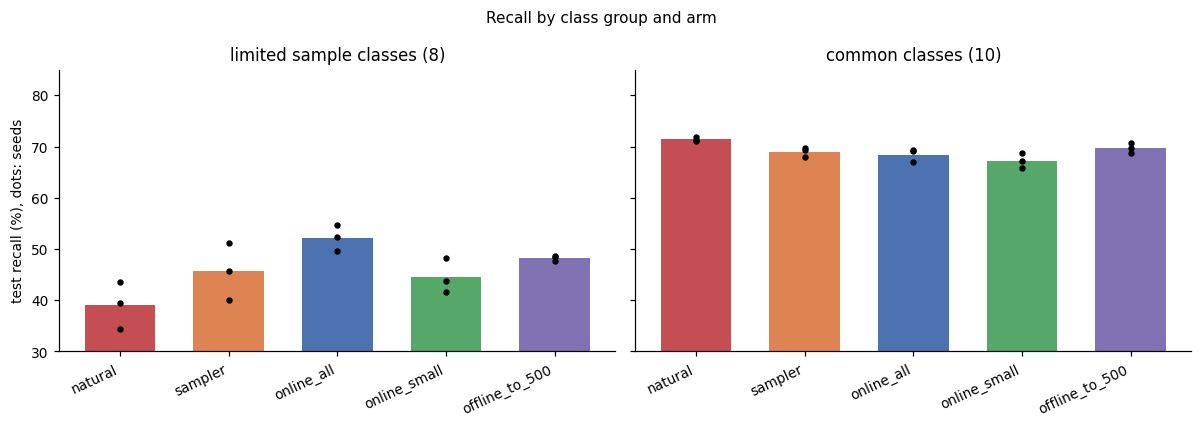

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
colours = dict(zip(ARM_ORDER, ["#c44e52", "#dd8452", "#4c72b0", "#55a868", "#8172b3"]))
for ax, col, title in zip(axes, ["limited sample recall", "common recall"],
                          [f"limited sample classes ({len(rare_ids)})", f"common classes ({len(common_ids)})"]):
    for i, arm in enumerate(ARM_ORDER):
        vals = 100 * seed_tables[arm][col].to_numpy()
        ax.bar(i, vals.mean(), color=colours[arm], width=0.65)
        ax.scatter(np.full(len(vals), i), vals, color="black", s=10, zorder=3)
    ax.set_xticks(range(len(ARM_ORDER)), ARM_ORDER, rotation=25, ha="right")
    ax.set_title(title)
    ax.set_ylim(30, 85)
axes[0].set_ylabel("test recall (%), dots: seeds")
fig.suptitle("Recall by class group and arm", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("recall by class group and arm", "test", figure=fig, iteration=0, report_interactive=False)
plt.show()

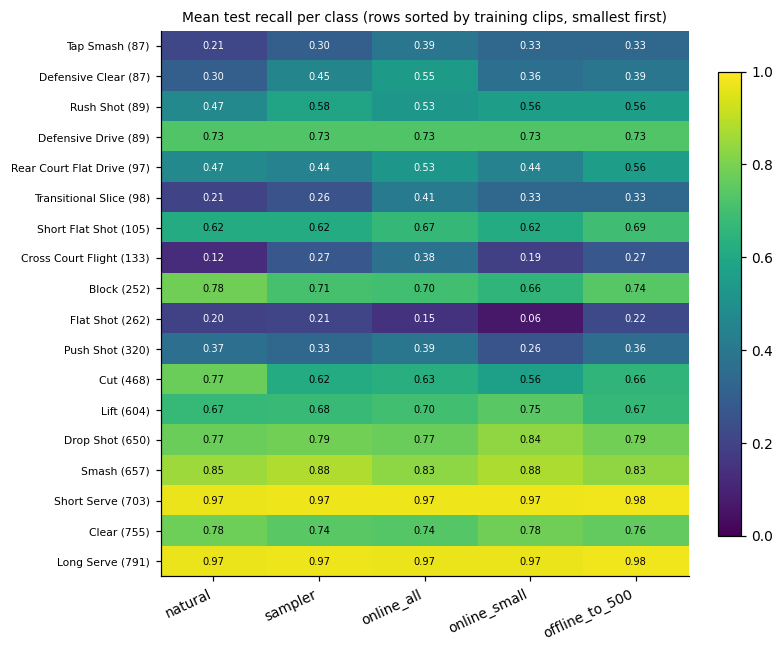

In [11]:
rec_by_arm = pd.DataFrame({a: per_class_recall(data[a]["correct"].mean(axis=0)) for a in ARM_ORDER}, index=class_names)
order = train_counts.sort_values().index
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(rec_by_arm.loc[order].values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(ARM_ORDER)), ARM_ORDER, rotation=25, ha="right")
ax.set_yticks(range(len(order)), [f"{short[c]} ({train_counts[c]})" for c in order], fontsize=7)
for i in range(len(order)):
    for j in range(len(ARM_ORDER)):
        v = rec_by_arm.loc[order].values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if v < 0.55 else "black")
ax.set_title("Mean test recall per class (rows sorted by training clips, smallest first)", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()
slog.report_matplotlib_figure("per class recall by arm", "test", figure=fig, iteration=0, report_interactive=False)
plt.show()
slog.report_table("per class test recall by arm", "test", iteration=0,
                  table_plot=rec_by_arm.loc[order].round(3).rename(index=short).reset_index().rename(columns={"index": "class"}))

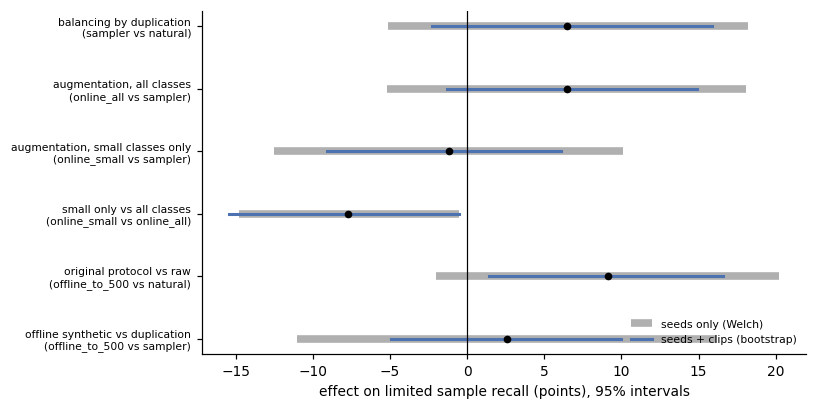

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
sel = contrast_table[contrast_table["group"] == "limited sample"].reset_index(drop=True)
parse = lambda s: [float(x) for x in s.strip("[]").split(",")]
for i, r in sel.iterrows():
    lo, hi = parse(r["seeds + clips 95% CI"])
    wl, wh = parse(r["seeds only Welch 95% CI"])
    e = float(r["effect (points)"])
    ax.plot([wl, wh], [i, i], color="#b0b0b0", lw=5, solid_capstyle="butt", label="seeds only (Welch)" if i == 0 else None)
    ax.plot([lo, hi], [i, i], color="#4c72b0", lw=2, label="seeds + clips (bootstrap)" if i == 0 else None)
    ax.plot(e, i, "ko", ms=4)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(sel)), [f"{r['contrast']}\n({r['arm A vs arm B']})" for _, r in sel.iterrows()], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("effect on limited sample recall (points), 95% intervals")
ax.legend(frameon=False, fontsize=7, loc="lower right")
fig.tight_layout()
slog.report_matplotlib_figure("contrasts on limited sample recall", "test", figure=fig, iteration=0, report_interactive=False)
plt.show()
task_s.upload_artifact("results", artifact_object=results_path)
task_s.close()

## How to read this

- A contrast is only a finding if both intervals exclude zero (the `clear` column). With three seeds the seed
  only interval is wide, and effects of a few points on the limited sample group will usually not clear it.
  That is a statement about how much evidence three seeds can give, not about the arms.
- If `sampler` vs `natural` is clear and the augmentation contrasts are not, the supportable claim is that
  balancing is what helps small classes, and augmentation has no demonstrated additional effect.
- If `online_small` or `offline_to_500` clears the sampler on limited sample recall, that is the result to
  build the paper around, with the caveat that the offline arm also differs in augmentation family.
- Whatever comes out, report all five arms. The raw `natural` arm is a legitimate baseline and is not altered
  to widen any gap.